# MDC_51006_EP - Foundations of Machine Learning - Lab 7

The goal of this lab is
- to explore some dimension reduction algorithms,
- to test the most classical clustering algorithms.

Once again, we will use the German credit dataset!

In [3]:
# !wget -nc https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv

In [4]:
import polars as pl

In [5]:
german_credit = pl.read_csv("german_credit_data_biased_training.csv")

In [6]:
import seaborn.objects as so

In [7]:
import polars.selectors as cs
string_columns = german_credit.select(cs.string()).columns
numerical_columns = german_credit.select(cs.numeric()).columns

In [12]:
german_credit.head(10)

CheckingStatus,LoanDuration,CreditHistory,LoanPurpose,LoanAmount,ExistingSavings,EmploymentDuration,InstallmentPercent,Sex,OthersOnLoan,CurrentResidenceDuration,OwnsProperty,Age,InstallmentPlans,Housing,ExistingCreditsCount,Job,Dependents,Telephone,ForeignWorker,Risk
str,i64,str,str,i64,str,str,i64,str,str,i64,str,i64,str,str,i64,str,i64,str,str,str
"""0_to_200""",31,"""credits_paid_to_date""","""other""",1889,"""100_to_500""","""less_1""",3,"""female""","""none""",3,"""savings_insurance""",32,"""none""","""own""",1,"""skilled""",1,"""none""","""yes""","""No Risk"""
"""less_0""",18,"""credits_paid_to_date""","""car_new""",462,"""less_100""","""1_to_4""",2,"""female""","""none""",2,"""savings_insurance""",37,"""stores""","""own""",2,"""skilled""",1,"""none""","""yes""","""No Risk"""
"""less_0""",15,"""prior_payments_delayed""","""furniture""",250,"""less_100""","""1_to_4""",2,"""male""","""none""",3,"""real_estate""",28,"""none""","""own""",2,"""skilled""",1,"""yes""","""no""","""No Risk"""
"""0_to_200""",28,"""credits_paid_to_date""","""retraining""",3693,"""less_100""","""greater_7""",3,"""male""","""none""",2,"""savings_insurance""",32,"""none""","""own""",1,"""skilled""",1,"""none""","""yes""","""No Risk"""
"""no_checking""",28,"""prior_payments_delayed""","""education""",6235,"""500_to_1000""","""greater_7""",3,"""male""","""none""",3,"""unknown""",57,"""none""","""own""",2,"""skilled""",1,"""none""","""yes""","""Risk"""
"""no_checking""",32,"""outstanding_credit""","""vacation""",9604,"""500_to_1000""","""greater_7""",6,"""male""","""co-applicant""",5,"""unknown""",57,"""none""","""free""",2,"""skilled""",2,"""yes""","""yes""","""Risk"""
"""no_checking""",9,"""prior_payments_delayed""","""car_new""",1032,"""100_to_500""","""4_to_7""",3,"""male""","""none""",4,"""savings_insurance""",41,"""none""","""own""",1,"""management_self-employed""",1,"""none""","""yes""","""No Risk"""
"""less_0""",16,"""credits_paid_to_date""","""vacation""",3109,"""less_100""","""4_to_7""",3,"""female""","""none""",1,"""car_other""",36,"""none""","""own""",2,"""skilled""",1,"""none""","""yes""","""No Risk"""
"""0_to_200""",11,"""credits_paid_to_date""","""car_new""",4553,"""less_100""","""less_1""",3,"""female""","""none""",3,"""savings_insurance""",22,"""none""","""own""",1,"""management_self-employed""",1,"""none""","""yes""","""No Risk"""


In [8]:
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

In [ ]:
categorical_features = string_columns.copy()
categorical_features.remove('Risk')

###
categorical_transformer = Pipeline(steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

### 
numerical_transformer = Pipeline(steps=[
        ('scaler', StandardScaler())
    ])

preprocessor = ColumnTransformer(
        transformers=[
            ('cat', categorical_transformer, categorical_features),
            ('num', numerical_transformer, numerical_columns)
        ],
        remainder='passthrough'
        # force_int_remainder_cols=False
    )

In [13]:
X = german_credit.drop('Risk')
y = german_credit['Risk']
LoanAmount = X['LoanAmount']

## Encoding and Dimension Reduction

We can use the `preprocessor`pipeline we have used before to transform the dataset into a *dataset of vectors*, i.e. a matrix.

In [18]:
X.shape

(5000, 20)

In [15]:
X_mat = preprocessor.fit_transform(X)

**Question** What is the dimension of those vectors?

**Answer** Using the `shape`attribute:

In [ ]:
X_mat.shape

(5000, 60)

We see that the dimension of those vectors is 60.

---

This dimension is (much) larger than 2 and thus it is hard to visualize our dataset with a single plot.

The most classical dimension reduction method is probably the Principal Component Analysis (PCA). It is available in scikit learn with

In [29]:
from sklearn.decomposition import PCA

In [30]:
### before doing pca , we need to transform our data into numerical matrix
X_mat.shape

(5000, 60)

In [31]:
pca = PCA(n_components=2)
X_PCA = pca.fit_transform(X_mat)

The resulting matrix has only 2 columns (a collection of vector of dimension 2) which can be visualized:

In [32]:
df_PCA = pl.DataFrame({ 'PC1': X_PCA[:,0], 'PC2': X_PCA[:,1], 'Risk': y})

In [33]:
df_PCA

PC1,PC2,Risk
f64,f64,str
-0.703369,-0.923726,"""No Risk"""
-1.624515,0.339743,"""No Risk"""
-1.150481,0.2542,"""No Risk"""
-0.711259,-0.68386,"""No Risk"""
1.968647,-0.712543,"""Risk"""
…,…,…
0.212633,-1.122555,"""No Risk"""
-1.218608,-0.47549,"""No Risk"""
4.299634,1.622983,"""Risk"""


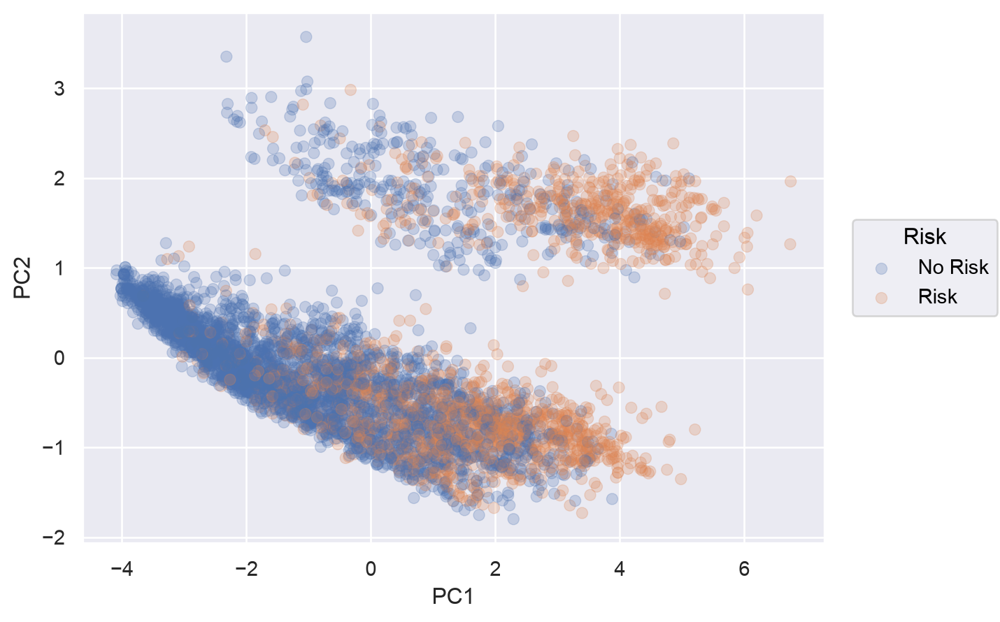

In [34]:
so.Plot(df_PCA, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

**Question** How different is the picture if you use the TSNE algorithm (included in scikit learn) or the UMAP one.

Please store the result of the TSNE in `X_TSNE` as this name is used below. In the meantime, we let


In [35]:
X_TSNE = X_PCA

so that the notebook runs...

**Answer**

In [36]:
from sklearn.manifold import TSNE

In [67]:
X_TSNE = TSNE(n_components=2, learning_rate='auto',

                  init='random', perplexity=3).fit_transform(X_mat)

In [68]:
df_TSNE = pl.DataFrame({ 'PC1': X_TSNE[:,0], 'PC2': X_TSNE[:,1], 'Risk': y})

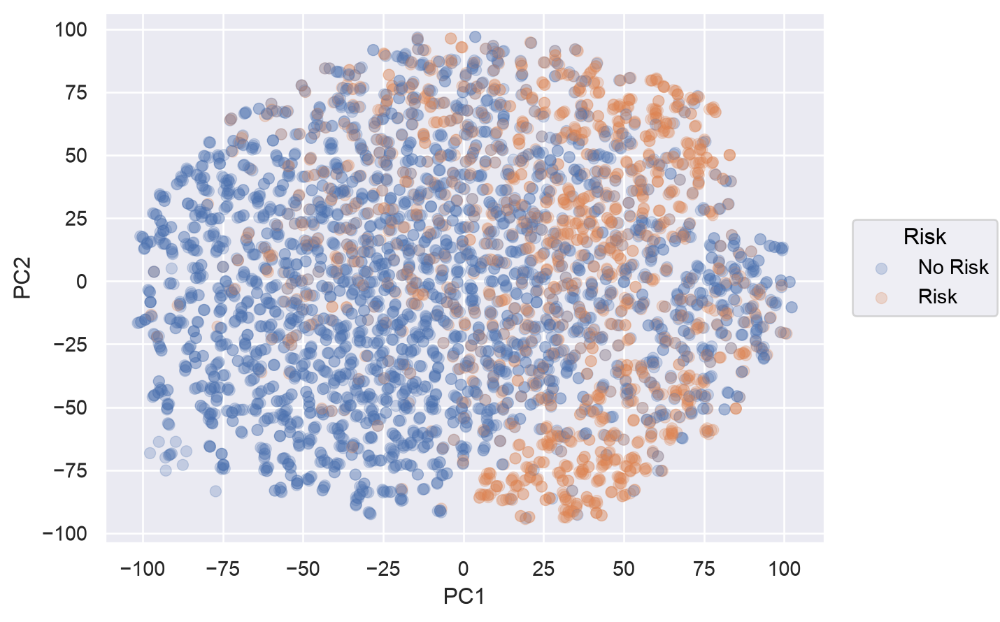

In [69]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

In [41]:
from umap import UMAP

In [49]:
X_UMAP = UMAP(n_components=2).fit_transform(X_mat)

In [50]:
df_UMAP = pl.DataFrame({ 'PC1': X_UMAP[:,0], 'PC2': X_UMAP[:,1], 'Risk': y})

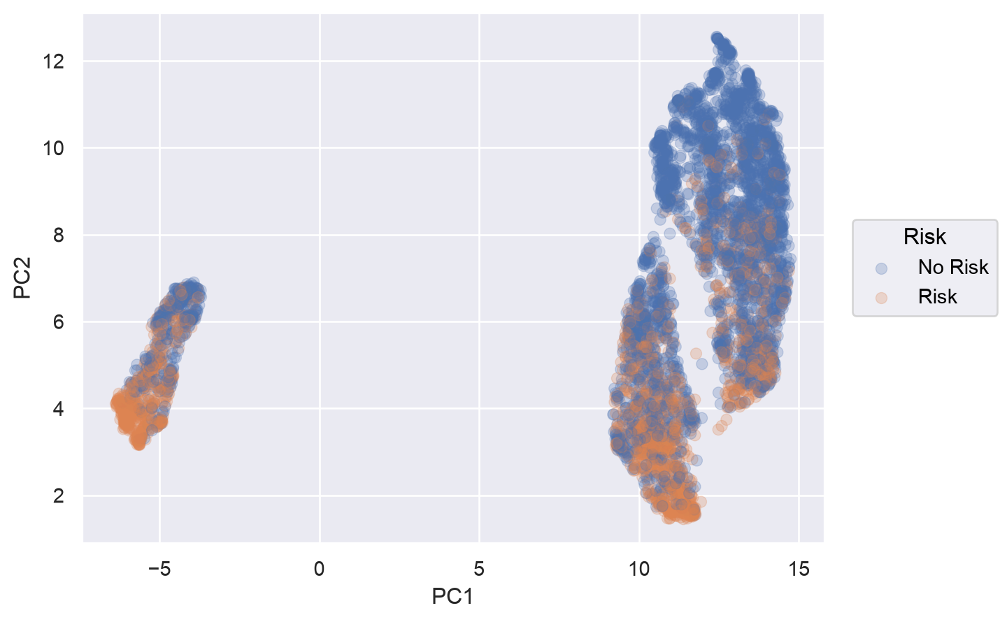

In [51]:
so.Plot(df_UMAP, x='PC1', y='PC2', color='Risk').add(so.Dot(alpha=.25))

---

**Question** Which representation is the best?

**Answer** None... As we have absolutely no idea how to use them properly...

---





## Clustering

We are going now to explore the most classical clustering algorithms starting with the k-means algorithm.

Once again relying on scikit learn, we obtain

In [52]:
from sklearn.cluster import KMeans

In [53]:
kmeans_PCA = KMeans(n_clusters=8, random_state=0, n_init="auto").fit(X_PCA)

We can now look at the obtained labels

In [54]:
kmeans_PCA.labels_

array([5, 1, 1, ..., 3, 5, 1], shape=(5000,), dtype=int32)

In [55]:
df_PCA

PC1,PC2,Risk
f64,f64,str
-0.703369,-0.923726,"""No Risk"""
-1.624515,0.339743,"""No Risk"""
-1.150481,0.2542,"""No Risk"""
-0.711259,-0.68386,"""No Risk"""
1.968647,-0.712543,"""Risk"""
…,…,…
0.212633,-1.122555,"""No Risk"""
-1.218608,-0.47549,"""No Risk"""
4.299634,1.622983,"""Risk"""


or better visualize them with

In [57]:
df_PCA = df_PCA.with_columns(pl.Series('Cluster', kmeans_PCA.labels_))

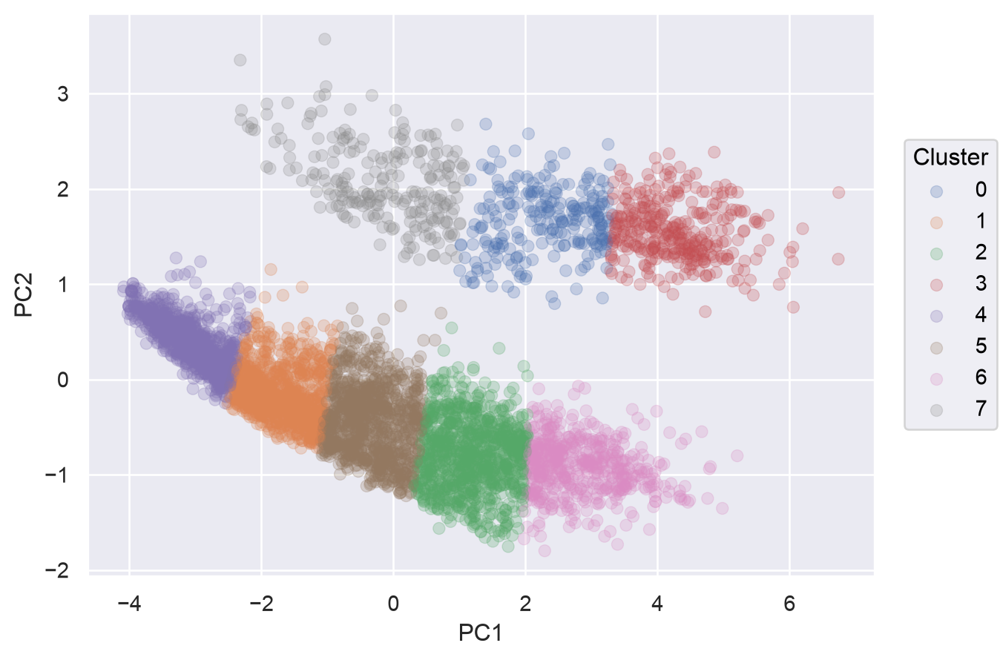

In [58]:
so.Plot(df_PCA, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

**Question** What is the result if we visualize the clustering using the TSNE representation or if we use the TSNE representation to do the clustering ?

**Answer**

In [70]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans_PCA.labels_))

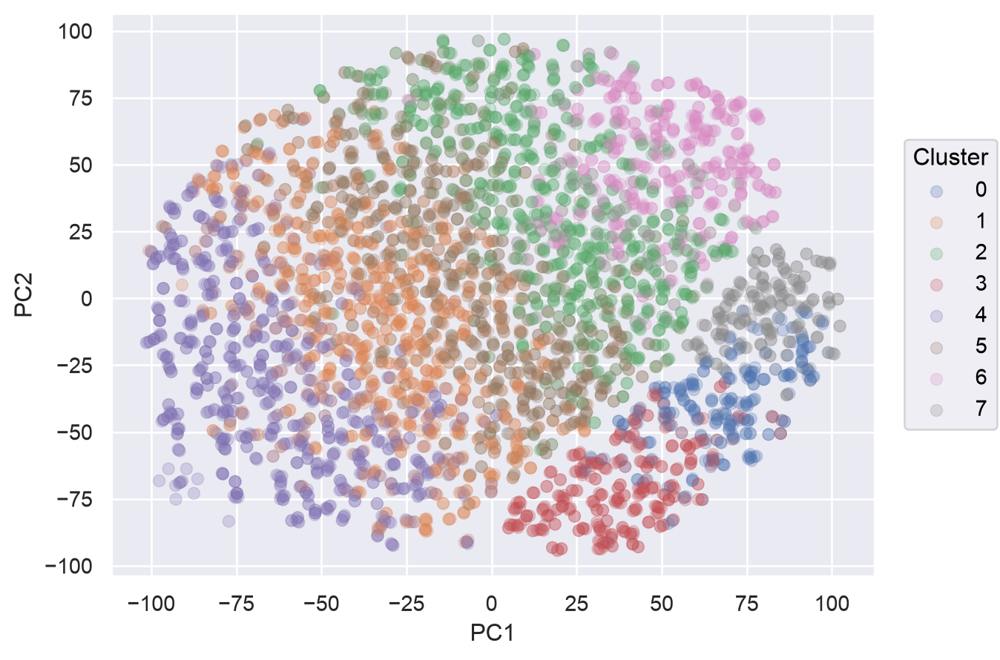

In [71]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

In [72]:
kmeans_TSNE = KMeans(n_clusters=8, random_state=0, n_init="auto").fit(X_TSNE)

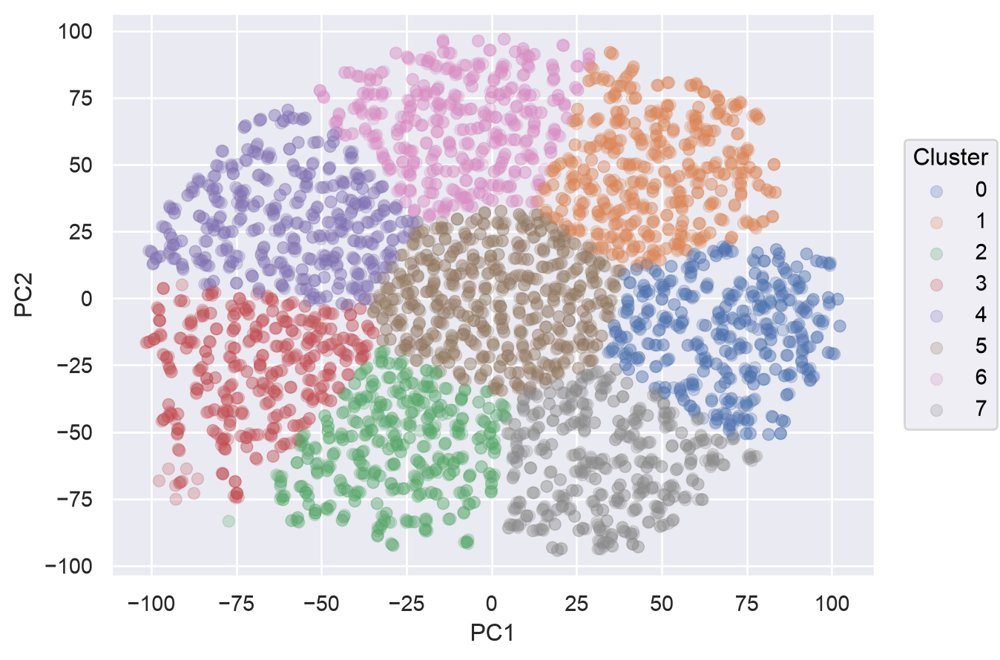

In [73]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans_TSNE.labels_))
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())


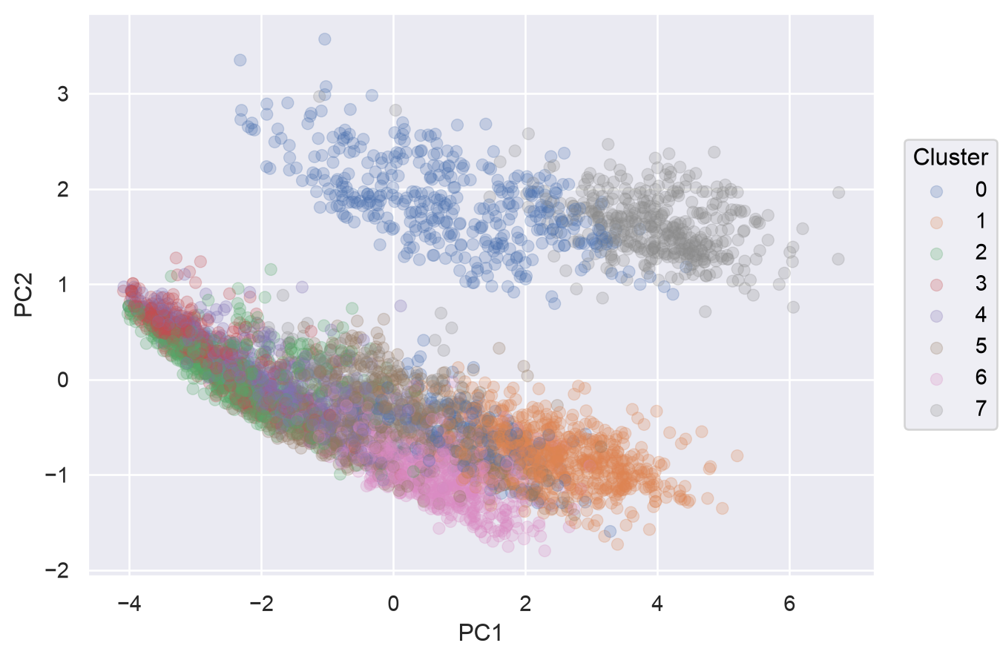

In [74]:
df_PCA = df_PCA.with_columns(pl.Series('Cluster', kmeans_TSNE.labels_))
so.Plot(df_PCA, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

---

**Question** How to visualize the agreement between the two clustering?

**Answer**

In [75]:
labels_df = pl.DataFrame({'PCA': kmeans_PCA.labels_, 'TSNE': kmeans_TSNE.labels_})

In [76]:
labels_df

PCA,TSNE
i32,i32
5,5
1,7
1,5
5,5
2,1
…,…
5,5
1,4
3,7


In [77]:
label_count_df = labels_df.group_by(['PCA','TSNE']).len().sort(['PCA', 'TSNE']).with_columns((pl.col('len')/ pl.col('len').sum()).alias('prop'))

In [78]:
label_count_df

PCA,TSNE,len,prop
i32,i32,u32,f64
0,0,170,0.034
0,7,79,0.0158
1,2,238,0.0476
1,3,126,0.0252
1,4,298,0.0596
…,…,…,…
6,1,454,0.0908
6,5,22,0.0044
6,6,24,0.0048


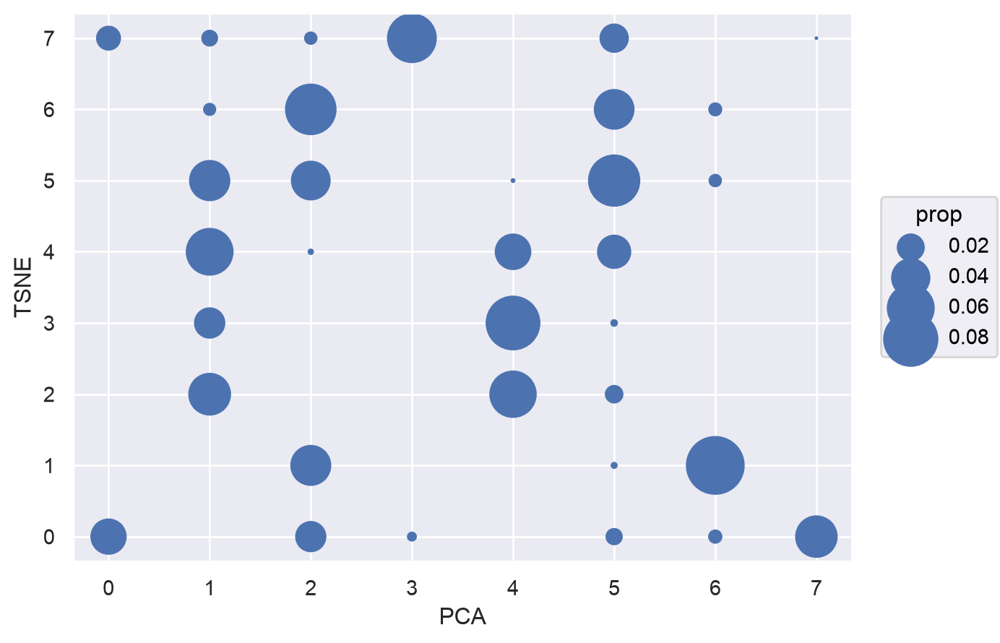

In [79]:
so.Plot(label_count_df, x='PCA', y='TSNE', pointsize='prop').add(so.Dot()).scale(pointsize=(0,30))

---

We can apply the same clustering algorithm 9 times with

In [80]:
import matplotlib.pyplot as plt

In [81]:
import seaborn as sns
sns.set()
fig = plt.figure(figsize=(10,10))



<Figure size 1000x1000 with 0 Axes>

In [82]:
for i in range(9):
  kmeans = KMeans(n_clusters=8, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  ax = fig.add_subplot(3,3,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).layout(size=(5,3)).on(ax).show()

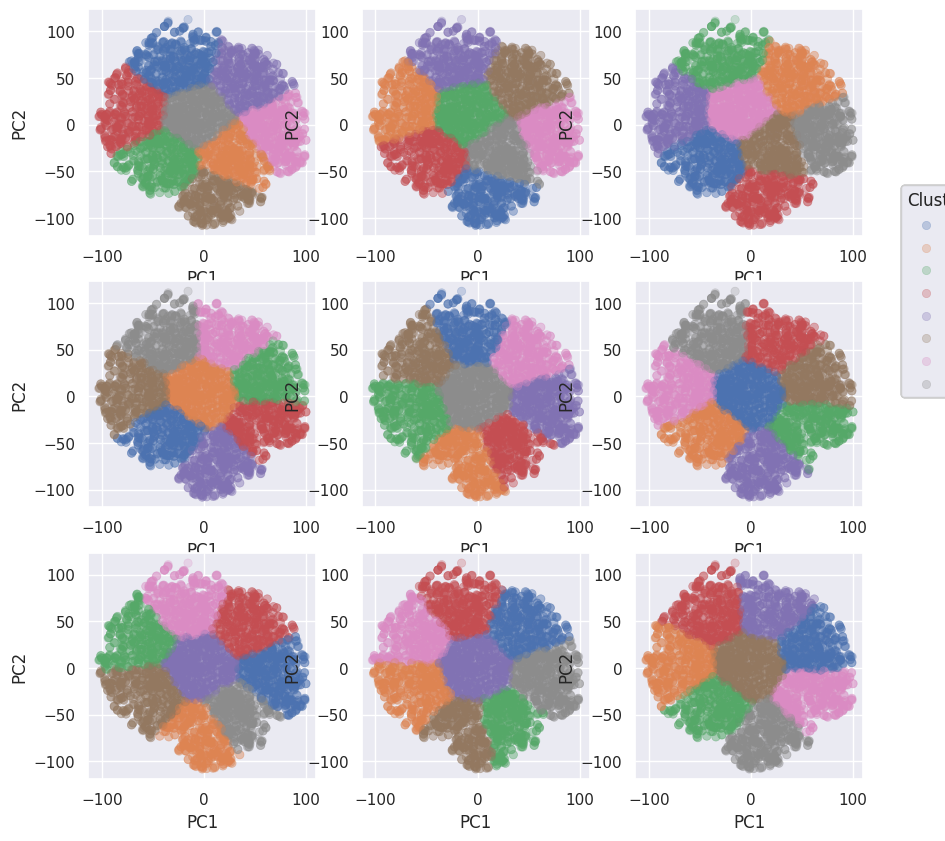

In [ ]:
fig

**Question** Why are the 9 results different?

**Answer** The k-means algorithm includes a random initialization and thus may lead to different results each time it is excecuted!

---

**Question** How do the clustering evolves when the number of components varies from 1 to 9 ?

**Answer**

In [83]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [84]:
for i in range(9):
  kmeans = KMeans(n_clusters=i+1, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  ax = fig.add_subplot(3,3,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).layout(size=(5,3)).on(ax).show()

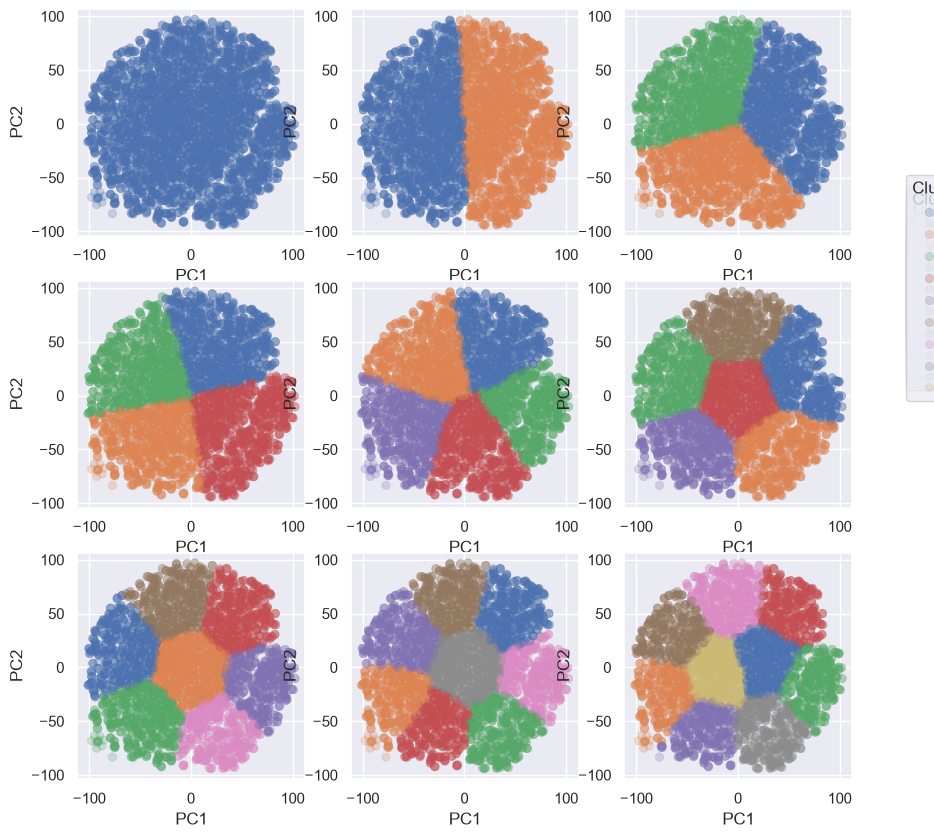

In [85]:
fig

---

A hierachical clustering strategy is also possible with Scikit Learn, for instance with

In [86]:
from sklearn.cluster import AgglomerativeClustering

In [87]:
clustering_TSNE = AgglomerativeClustering(n_clusters=8).fit(X_TSNE)

In [88]:
clustering_TSNE.labels_

array([0, 1, 1, ..., 2, 0, 1], shape=(5000,))

In [89]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_TSNE.labels_))

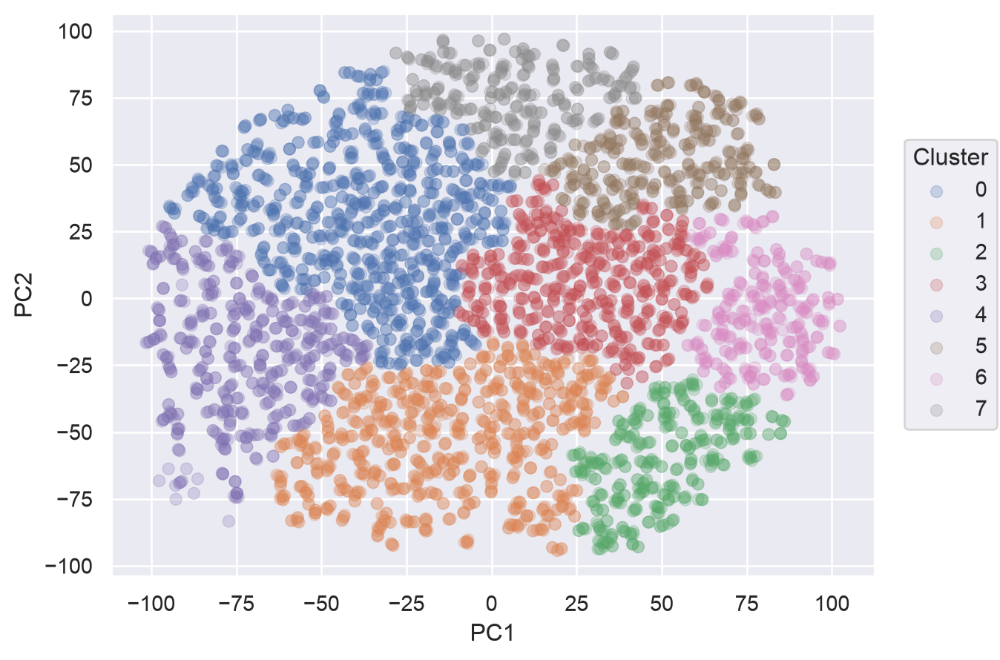

In [90]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

---

**Question** Compare the results of this algoritm with the ward, average, complete and single linkage method.

**Answer**

In [91]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [92]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  clustering_TSNE = AgglomerativeClustering(n_clusters=8, linkage=linkage_method).fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_TSNE.labels_))
  ax = fig.add_subplot(2,2,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).label(title=linkage_method).on(ax).show()

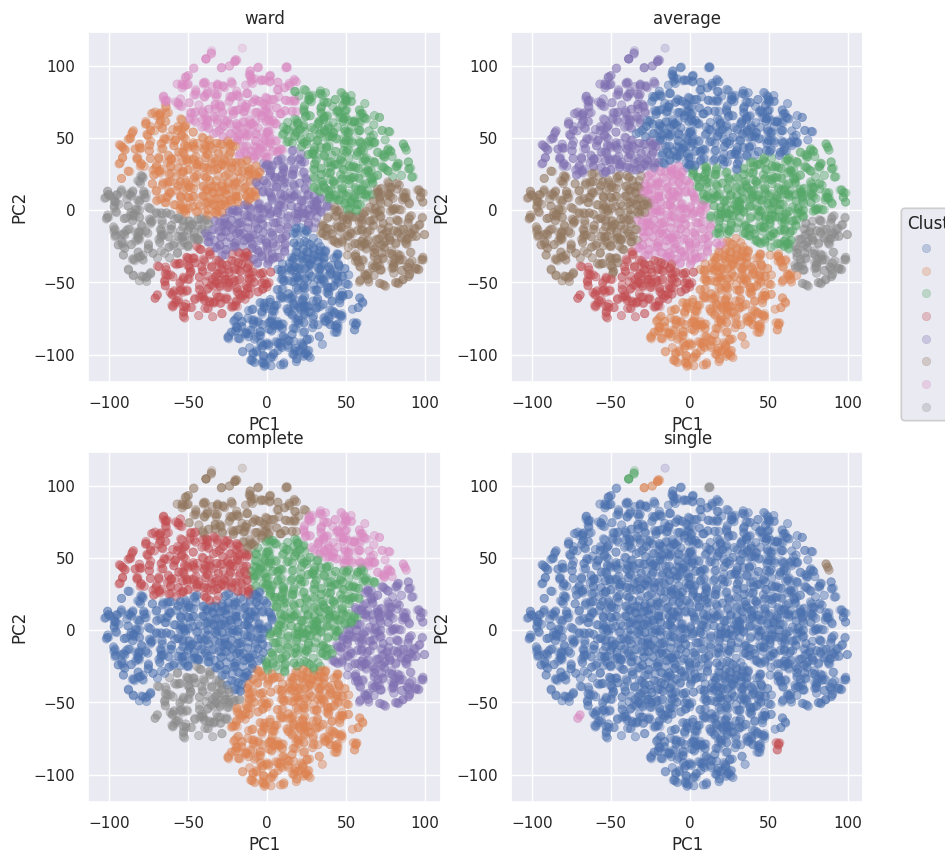

In [ ]:
fig

---

It exists a better implementation of the hierarchical clustering algorithm  in the `fastcluster` library. It works as follows

In [93]:
! pip install fastcluster

In [94]:
from fastcluster import linkage

In [95]:
X_linkage = linkage(X_TSNE, method='ward', metric='euclidean')

In [96]:
from scipy.cluster.hierarchy import dendrogram, fcluster

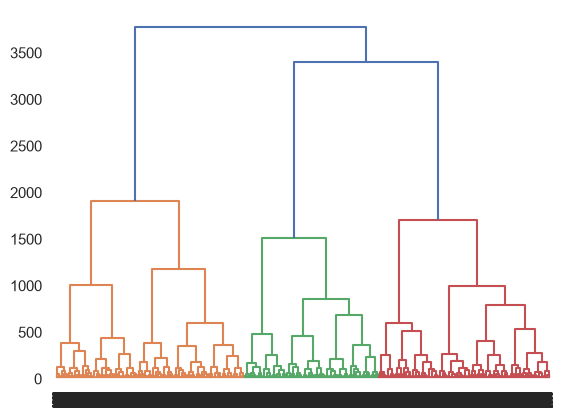

In [97]:
dn = dendrogram(X_linkage)

In [98]:
labels_ = fcluster(X_linkage, t=8, criterion='maxclust')

In [99]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', labels_))

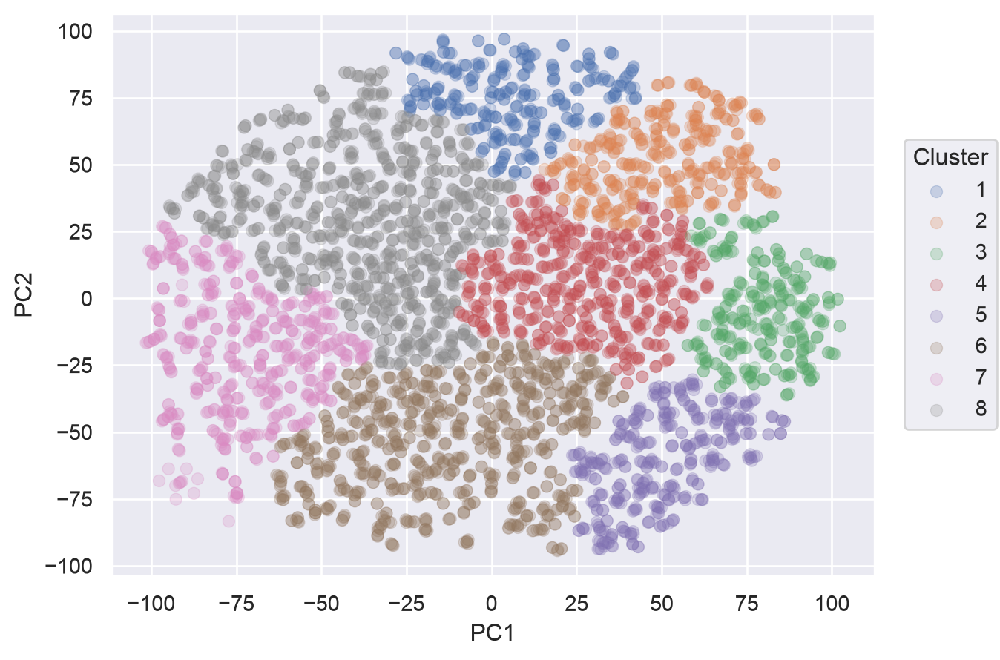

In [100]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal())

In [101]:
fig = plt.figure(figsize=(10,15))
fig.clf()

<Figure size 1000x1500 with 0 Axes>

Note in particular that the number of components is chosen after a full tree is build, so that we can test efficiently several choices for this number of components

In [102]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  X_linkage = linkage(X_TSNE, method=linkage_method, metric='euclidean')
  for j in range(1,10):
    labels_ = fcluster(X_linkage, t=j, criterion='maxclust')
    df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', labels_))
    ax = fig.add_subplot(10,4, 1+i+4*(j-1) )
    so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25)).scale(color=so.Nominal()).label(title=linkage_method).on(ax).show()

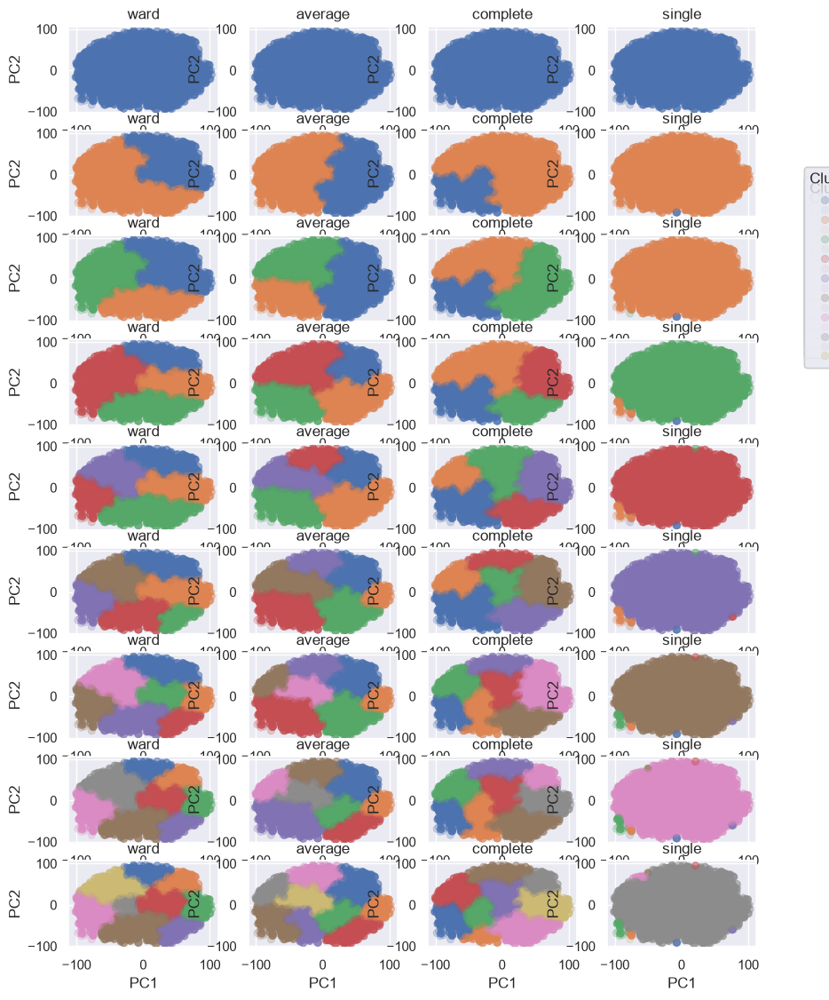

In [103]:
fig

**Question** What about the HDSCAN method ?

You can use $.1$ for the value of alpha.

**Answer**

In [104]:
from sklearn.cluster import HDBSCAN

In [105]:
clustering_HDBSCAN = HDBSCAN(alpha=.1).fit(X_TSNE)

/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [106]:
clustering_HDBSCAN.labels_

array([321, 256, 510, ...,  65, 270, 240], shape=(5000,))

In [107]:
df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering_HDBSCAN.labels_))

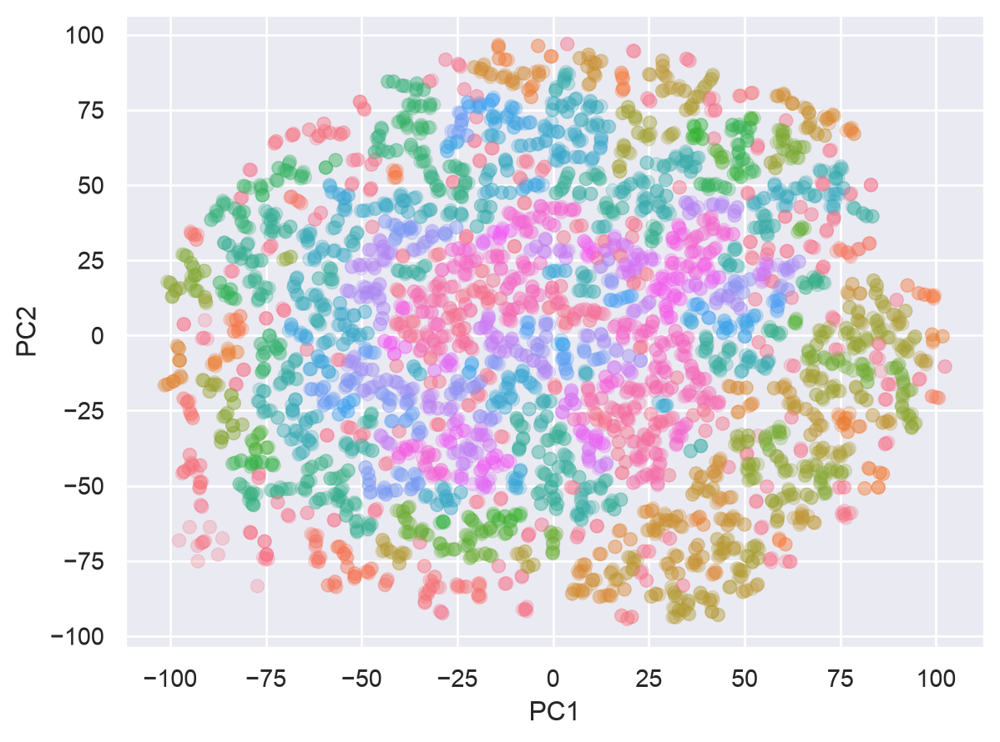

In [108]:
so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25), legend=False).scale(color=so.Nominal())

**Question** Is there a better choice for the parameter alpha ?

**Answer**

In [109]:
fig = plt.figure(figsize=(10,10))

<Figure size 1000x1000 with 0 Axes>

In [110]:
for i, alpha in enumerate([0.01, 0.1, 1, 10]):
  clustering = HDBSCAN(alpha=alpha).fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', clustering.labels_))
  ax = fig.add_subplot(2,2,i+1)
  so.Plot(df_TSNE, x='PC1', y='PC2', color='Cluster').add(so.Dot(alpha=.25), legend=False).scale(color=so.Nominal()).label(title=alpha).on(ax).show()

/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


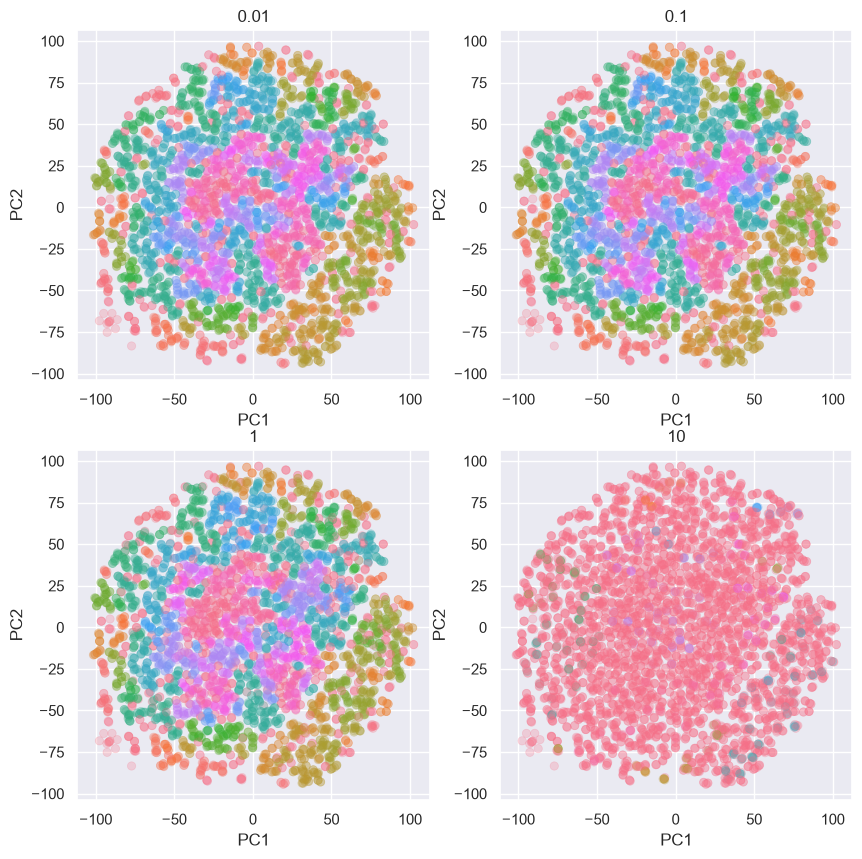

In [111]:
fig

---

**Question** Can you compare those clustering methods with some metrics proposed by scikit learn?

**Answer**

In [112]:
from sklearn import metrics

In [113]:
df_clustering = pl.DataFrame()

In [114]:
for i in range(9):
  kmeans = KMeans(n_clusters=i+2, n_init="auto").fit(X_TSNE)
  df_TSNE = df_TSNE.with_columns(pl.Series('Cluster', kmeans.labels_))
  df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'Kmeans', 'n_clusters': i+2, 'silhouette': metrics.silhouette_score(X_TSNE, kmeans.labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, kmeans.labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, kmeans.labels_)})]
  )

In [115]:
df_clustering

name,n_clusters,silhouette,calinski_harabasz,davies_bouldin
str,i64,f64,f64,f64
"""Kmeans""",2,0.350338,3039.008443,1.169851
"""Kmeans""",3,0.380962,3984.65772,0.858109
"""Kmeans""",4,0.358906,4110.497091,0.862853
"""Kmeans""",5,0.335552,4042.830232,0.894237
"""Kmeans""",6,0.357979,4103.308116,0.800664
"""Kmeans""",7,0.368331,4420.555451,0.771657
"""Kmeans""",8,0.360981,4290.404557,0.814452
"""Kmeans""",9,0.35931,4387.748373,0.811786
"""Kmeans""",10,0.34557,4328.627578,0.832776


In [116]:
for i, linkage_method in enumerate(['ward', 'average', 'complete', 'single']):
  X_linkage = linkage(X_TSNE, method=linkage_method, metric='euclidean')
  for j in range(1,10):
    labels_ = fcluster(X_linkage, t=j+1, criterion='maxclust')
    df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'Hierarchical_'+linkage_method, 'n_clusters': j+2, 'silhouette': metrics.silhouette_score(X_TSNE, labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, labels_)})]
  )

In [117]:
df_clustering

name,n_clusters,silhouette,calinski_harabasz,davies_bouldin
str,i64,f64,f64,f64
"""Kmeans""",2,0.350338,3039.008443,1.169851
"""Kmeans""",3,0.380962,3984.65772,0.858109
"""Kmeans""",4,0.358906,4110.497091,0.862853
"""Kmeans""",5,0.335552,4042.830232,0.894237
"""Kmeans""",6,0.357979,4103.308116,0.800664
…,…,…,…,…
"""Hierarchical_single""",7,-0.287983,34.115949,0.655068
"""Hierarchical_single""",8,-0.293783,28.663905,0.639797
"""Hierarchical_single""",9,-0.358489,26.266773,0.647966


In [118]:
for i, alpha in enumerate([0.01, 0.05, 0.1, 0.5, 1, 5, 10]):
  clustering = HDBSCAN(alpha=alpha).fit(X_TSNE)
  df_clustering = pl.concat(
      [df_clustering,
      pl.DataFrame({'name': 'HDBSCAN', 'n_clusters': len(set(clustering.labels_)),
                    'silhouette': metrics.silhouette_score(X_TSNE, clustering.labels_),
                    'calinski_harabasz': metrics.calinski_harabasz_score(X_TSNE, clustering.labels_),
                    'davies_bouldin': metrics.davies_bouldin_score(X_TSNE, clustering.labels_)})]
  )

/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt/anaconda3/envs/gds_test/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/opt

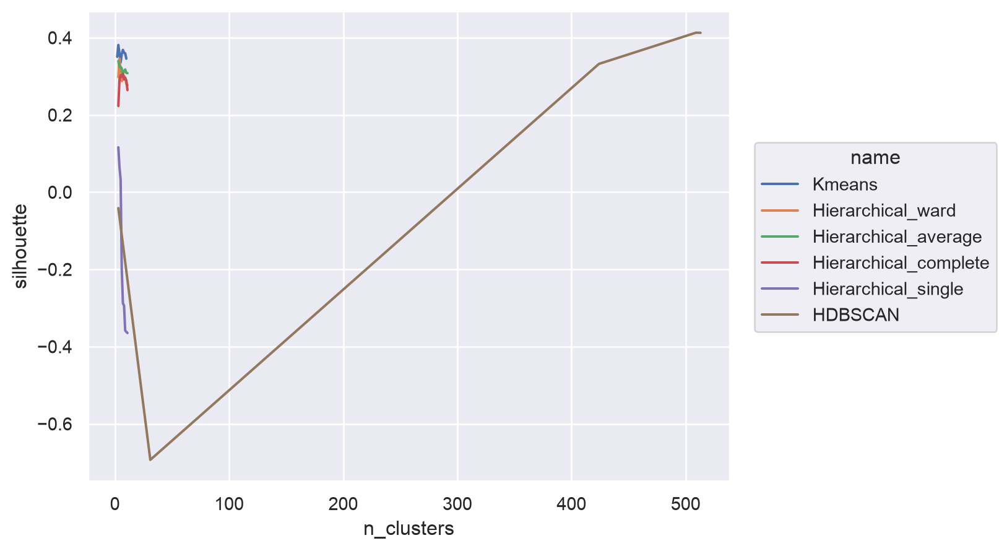

In [119]:
so.Plot(df_clustering, x='n_clusters', y='silhouette', color='name').add(so.Line()).scale(color=so.Nominal())

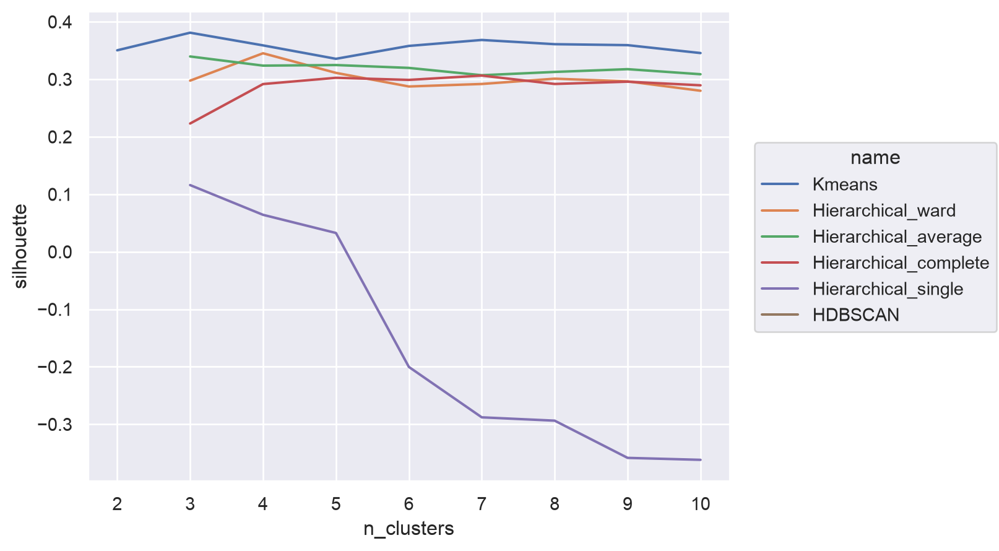

In [120]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='silhouette', color='name').add(so.Line()).scale(color=so.Nominal())

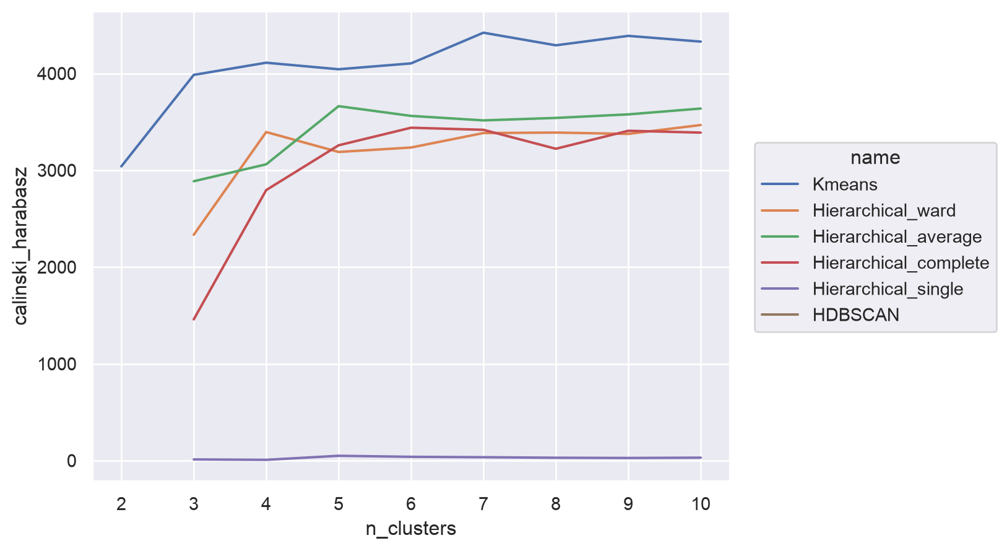

In [121]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='calinski_harabasz', color='name').add(so.Line()).scale(color=so.Nominal())

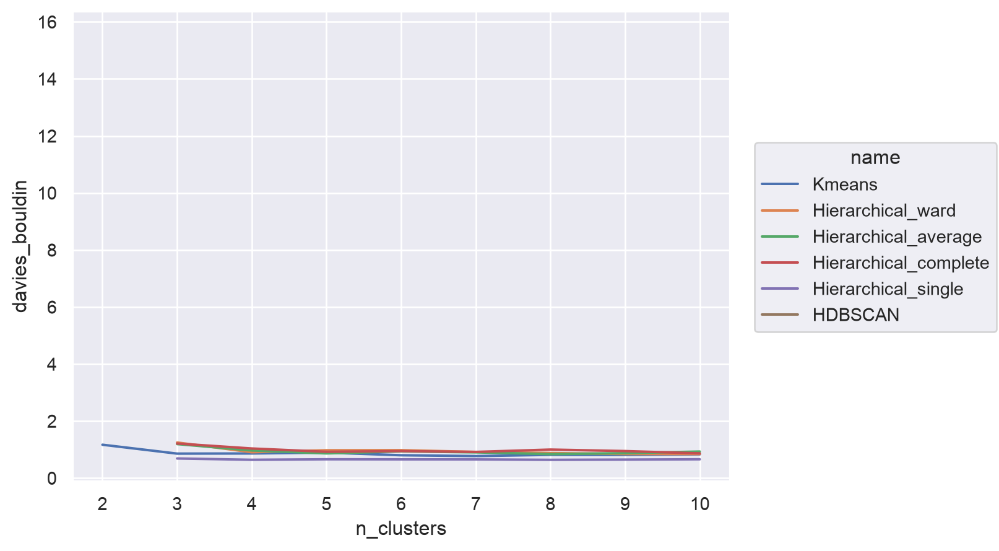

In [122]:
so.Plot(df_clustering.filter(pl.col('n_clusters')<=10), x='n_clusters', y='davies_bouldin', color='name').add(so.Line()).scale(color=so.Nominal())


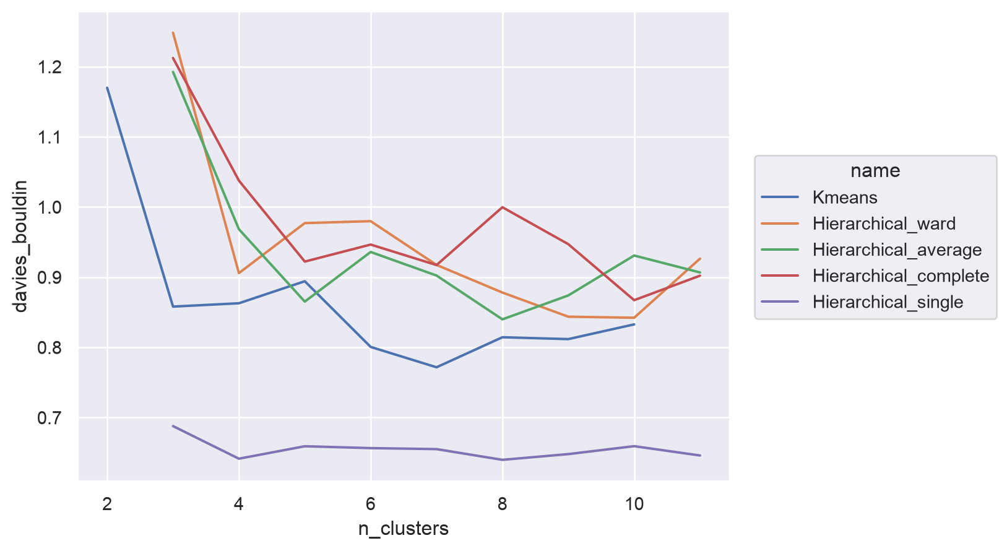

In [123]:
so.Plot(df_clustering.filter(~(pl.col('name')=='HDBSCAN')), x='n_clusters', y='davies_bouldin', color='name').add(so.Line()).scale(color=so.Nominal())


---